# 04 — Model Validation and Champion Decision

A stronger validation notebook does more than rank point estimates. It asks whether a challenger
improves discrimination on the **same applicants**, whether probabilities remain useful, and
whether the evidence is strong enough to justify opening the locked test.

**Controls used here**

- fixed validation population from Notebooks 02–03;
- paired comparisons because every model scored the same rows;
- bootstrap uncertainty around AUC lift;
- calibration diagnostics alongside ranking metrics;
- pre-registered promotion gates;
- no access to the test split.

**Inputs:** the validation predictions saved by Notebook 03. Reusing saved predictions guarantees
that statistical comparisons use identical applicants and avoids retraining until a favorable draw
appears. The current evidence is internal validation on a stratified random split, not out-of-time
or external validation.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve


def find_project_root() -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "pyproject.toml").exists():
            return candidate
    raise FileNotFoundError("Run this notebook from the project or notebook directory")


PROJECT_ROOT = find_project_root()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from credit_risk_champion_challenger.evaluation import (  # noqa: E402
    evaluate_binary_classifier,
    paired_bootstrap_difference,
)
from credit_risk_champion_challenger.governance import compare_candidate  # noqa: E402

PREDICTIONS_PATH = PROJECT_ROOT / "reports" / "notebook3_validation_predictions.csv"
predictions = pd.read_csv(PREDICTIONS_PATH)
predictions.head()

,SK_ID_CURR,TARGET,logistic_probability,xgboost_probability,lightgbm_probability
0,100011,0,0.052297,0.055185,0.054401
1,100012,0,0.044191,0.035778,0.036201
2,100015,0,0.024565,0.019249,0.019995
3,100018,0,0.050918,0.033275,0.035158
4,100020,0,0.360833,0.544543,0.516369


## 1. Rebuild the common validation scorecard

ROC-AUC and KS describe rank ordering. Average precision focuses attention on the minority default
class. Brier score measures probability error; lower is better. None should be interpreted alone.

In [2]:
probability_columns = {
    "Logistic Regression": "logistic_probability",
    "XGBoost": "xgboost_probability",
    "LightGBM": "lightgbm_probability",
}

y_validation = predictions["TARGET"].to_numpy()
metrics = {
    model: evaluate_binary_classifier(y_validation, predictions[column].to_numpy())
    for model, column in probability_columns.items()
}
scorecard = pd.DataFrame(metrics).T.sort_values("roc_auc", ascending=False)
scorecard.style.format("{:.4f}").highlight_max(
    subset=["roc_auc", "average_precision", "ks_statistic"], color="#d1fae5"
).highlight_min(subset=["brier_score"], color="#d1fae5")

,roc_auc,average_precision,brier_score,ks_statistic
XGBoost,0.7454,0.2334,0.0684,0.3680
LightGBM,0.7447,0.2328,0.0684,0.3654
Logistic Regression,0.7293,0.2094,0.0695,0.3437


## 2. Quantify paired challenger lift

A raw difference can be noise. Resampling applicant rows **as pairs** preserves the relationship
between each model's scores and produces a confidence interval for candidate-minus-champion AUC.

In [3]:
champion_probability = predictions["logistic_probability"].to_numpy()
bootstrap_rows = []

for model in ["XGBoost", "LightGBM"]:
    result = paired_bootstrap_difference(
        y_validation,
        champion_probability,
        predictions[probability_columns[model]].to_numpy(),
        n_resamples=500,
        random_state=42,
    )
    bootstrap_rows.append({"candidate": model, **result})

bootstrap_results = pd.DataFrame(bootstrap_rows).set_index("candidate")
bootstrap_results.style.format("{:.4f}")

,difference,ci_low,ci_high,probability_candidate_better
candidate,,,,
XGBoost,0.0161,0.0134,0.0188,1.0000
LightGBM,0.0155,0.0127,0.0182,1.0000


The interval answers a narrow question: whether ranking performance improved on this validation
population. It does not prove temporal stability, transportability to another lender, or business
value at a chosen approval policy.

In this run, both challengers have confidence intervals entirely above zero. XGBoost's observed AUC
lift over Logistic Regression is about **0.016**, which is statistically clear on this validation
sample but still requires a judgment about whether it is operationally material.

## 3. Inspect calibration

Credit decisions depend on probability quality, not only ordering. Quantile bins are useful here
because the default class is uncommon and equal-width bins can be nearly empty.

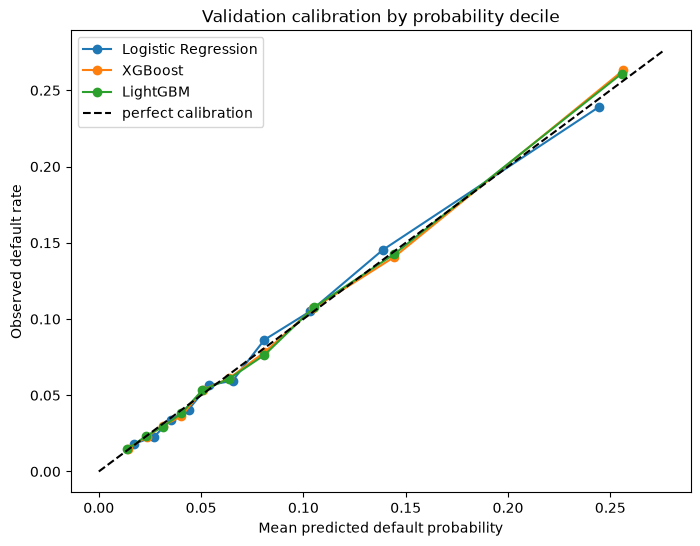

,expected_calibration_error
model,
Logistic Regression,0.0037
XGBoost,0.0028
LightGBM,0.0025


In [4]:
def expected_calibration_error(y_true, probability, bins=10):
    table = pd.DataFrame({"y": y_true, "p": probability})
    table["bin"] = pd.qcut(table["p"], q=bins, duplicates="drop")
    grouped = table.groupby("bin", observed=True).agg(
        observed=("y", "mean"), predicted=("p", "mean"), n=("y", "size")
    )
    return float(
        (grouped["n"] / grouped["n"].sum() * abs(grouped["observed"] - grouped["predicted"])).sum()
    )


fig, ax = plt.subplots(figsize=(8, 6))
calibration_rows = []
for model, column in probability_columns.items():
    observed, predicted = calibration_curve(
        y_validation, predictions[column], n_bins=10, strategy="quantile"
    )
    ax.plot(predicted, observed, marker="o", label=model)
    calibration_rows.append(
        {
            "model": model,
            "expected_calibration_error": expected_calibration_error(
                y_validation, predictions[column]
            ),
        }
    )

limit = max(ax.get_xlim()[1], ax.get_ylim()[1])
ax.plot([0, limit], [0, limit], "--", color="black", label="perfect calibration")
ax.set(xlabel="Mean predicted default probability", ylabel="Observed default rate")
ax.set_title("Validation calibration by probability decile")
ax.legend()
plt.show()

pd.DataFrame(calibration_rows).set_index("model").style.format("{:.4f}")

## 4. Apply the promotion policy

These gates were defined before touching the locked test. Passing them means “advance for final
evaluation,” not “deploy.”

In [5]:
champion_metrics = metrics["Logistic Regression"]
decisions = []
for candidate in ["XGBoost", "LightGBM"]:
    result = compare_candidate(champion_metrics, metrics[candidate])
    decisions.append(
        {
            "candidate": candidate,
            "decision": result["validation_decision"],
            "production_status": result["production_status"],
            **{f"gate_{name}": passed for name, passed in result["gates"].items()},
        }
    )

pd.DataFrame(decisions).set_index("candidate")

,decision,production_status,gate_auc_lift,gate_average_precision,gate_ks,gate_calibration
candidate,,,,,,
XGBoost,advance_to_locked_test,not_promoted,True,True,True,True
LightGBM,advance_to_locked_test,not_promoted,True,True,True,True


## Validation conclusion

XGBoost is the leading candidate because it has the strongest validation ROC-AUC and average
precision, improves Brier score and KS, and clears the paired-evidence gate. Logistic Regression
remains the champion until the selected candidate passes the one-time locked test, fairness and
segment review, stability checks, reproducibility review, and human approval.

**Remaining limitations:** bootstrap intervals quantify sampling uncertainty only; they do not cover
hyperparameter search, dataset shift, label-definition error, or correlated/repeated borrowers.
Calibration was assessed graphically and with ECE, but a calibration method has not been fitted.
Because model selection used validation, any final performance claim must come from the untouched
test set or, preferably, later out-of-time data.